# Bank Marketing Intelligence & Campaign Effectiveness Analytics

### 1. Project Overview

**Industry:** Banking & Financial Services  
**Project Type:** Marketing Analytics | Customer Segmentation | Business Intelligence  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, MySQL

### 2. Business Problem

Banks conduct direct marketing campaigns through channels such as cellular and telephone calls to promote financial products, including term deposits. However, contacting every customer with the same strategy may lead to inefficient resource allocation and lower campaign effectiveness.

This project analyses historical bank marketing campaign data to identify customer segments, communication channels and campaign characteristics associated with higher subscription rates.

The objective is to generate actionable insights that can support better customer targeting and more effective marketing strategies.

### 3. Project Objectives

- Evaluate the overall effectiveness of marketing campaigns using subscription conversion rates.
- Identify customer segments with higher subscription propensity based on age and occupation.
- Compare campaign performance across different contact channels.
- Investigate the relationship between previous campaign outcomes and current subscriptions.
- Analyse how contact frequency is associated with subscription behaviour.
- Examine monthly variations in campaign performance.
- Translate analytical findings into data-driven business recommendations.

### 4. Dataset Description

**Dataset:** Bank Marketing Dataset  
**Source:** UCI Machine Learning Repository  
**Link:** https://archive.ics.uci.edu/dataset/222/bank+marketing

The analysis uses the `bank-full.csv` dataset.

| Attribute | Description |
|---|---|
| Records | 45,211 |
| Original features | 16 predictors + 1 target |
| Target variable | `y` |
| Target categories | Yes / No |
| Domain | Direct bank marketing campaigns |

The target variable indicates whether a customer subscribed to a term deposit following the marketing campaign.

### 5. Analytical Approach

The project follows a structured analytics workflow:

1. Data acquisition and initial inspection.
2. Data quality assessment and preprocessing.
3. Exploratory data analysis (EDA).
4. Feature engineering and customer segmentation.
5. SQL-based campaign performance analysis using MySQL.
6. Data visualization and dashboard development.
7. Business insights and recommendations.

### 6. Expected Business Outcome

The analysis aims to help identify promising customer segments, understand differences in campaign performance and highlight opportunities to improve marketing resource allocation through data-driven decision-making.

**Note:** The analysis identifies historical associations rather than causal effects. Campaign expenditure is not available in the dataset, so financial ROI cannot be directly calculated.

In [3]:

import urllib.request
import zipfile
import io
import pandas as pd

url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

response = urllib.request.urlopen(url)
z = zipfile.ZipFile(io.BytesIO(response.read()))

print(z.namelist())


['bank.zip', 'bank-additional.zip']


In [4]:

# Find the full dataset inside the archive
file_name = [
    f for f in z.namelist()
    if f.endswith("bank-full.csv")
]

print(file_name)


[]


In [6]:
import zipfile
import io

# Extract bank.zip from the outer archive and open it
with z.open('bank.zip') as nested_zip_bytes:
    with zipfile.ZipFile(io.BytesIO(nested_zip_bytes.read())) as z_inner:
        # Read the bank-full.csv file inside the inner zip
        with z_inner.open('bank-full.csv') as f:
            df = pd.read_csv(f, sep=";")

print("Verified shape:", df.shape)

Verified shape: (45211, 17)


In [7]:

# 1. Dataset dimensions
print("Shape:", df.shape)

# 2. Data types
print("\nData types:")
print(df.dtypes)

# 3. Missing values
print("\nMissing values:")
print(df.isnull().sum())

# 4. Duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# 5. Target distribution
print("\nSubscription distribution:")
print(df["y"].value_counts())

# 6. Target percentage
print("\nSubscription percentage:")
print(df["y"].value_counts(normalize=True) * 100)

# 7. Statistical summary
display(df.describe(include="all").T)


Shape: (45211, 17)

Data types:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

Missing values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Duplicate records: 0

Subscription distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Subscription percentage:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


In [8]:

# Create a working copy
bank = df.copy()

# 1. Standardize column names
bank.columns = bank.columns.str.strip().str.lower()

# 2. Rename columns
bank.rename(columns={
    "default": "credit_default",
    "y": "subscribed"
}, inplace=True)

# 3. Binary target encoding
bank["subscribed_binary"] = (
    bank["subscribed"].map({"yes": 1, "no": 0})
)

# 4. Customer age segmentation
bank["age_group"] = pd.cut(
    bank["age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "55+"]
)

# 5. Contact frequency segmentation
bank["contact_group"] = pd.cut(
    bank["campaign"],
    bins=[0, 1, 3, 5, np.inf],
    labels=["1 contact", "2-3 contacts",
            "4-5 contacts", "6+ contacts"]
)

# 6. Previous campaign contact indicator
bank["previously_contacted"] = np.where(
    bank["pdays"] == -1, 0, 1
)

# 7. Previous campaign success indicator
bank["has_previous_success"] = np.where(
    bank["poutcome"] == "success", 1, 0
)

# Verify
print("New dataset shape:", bank.shape)
print("\nNew columns:")
print(bank.columns.tolist())

display(bank.head())


New dataset shape: (45211, 22)

New columns:
['age', 'job', 'marital', 'education', 'credit_default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'subscribed', 'subscribed_binary', 'age_group', 'contact_group', 'previously_contacted', 'has_previous_success']


,age,job,marital,education,credit_default,balance,housing,loan,contact,day,...,campaign,pdays,previous,poutcome,subscribed,subscribed_binary,age_group,contact_group,previously_contacted,has_previous_success
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,...,1,-1,0,unknown,no,0,55+,1 contact,0,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,...,1,-1,0,unknown,no,0,36-45,1 contact,0,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,...,1,-1,0,unknown,no,0,26-35,1 contact,0,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,...,1,-1,0,unknown,no,0,46-55,1 contact,0,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,...,1,-1,0,unknown,no,0,26-35,1 contact,0,0


In [9]:
print(bank["subscribed_binary"].value_counts())
print(bank["age_group"].value_counts())
print(bank["contact_group"].value_counts())
print(bank["previously_contacted"].value_counts())
print(bank["has_previous_success"].value_counts())

print("Missing values:", bank.isnull().sum().sum())

subscribed_binary
0    39922
1     5289
Name: count, dtype: int64
age_group
26-35    15571
36-45    13856
46-55     9548
55+       4900
18-25     1336
Name: count, dtype: int64
contact_group
2-3 contacts    18026
1 contact       17544
4-5 contacts     5286
6+ contacts      4355
Name: count, dtype: int64
previously_contacted
0    36954
1     8257
Name: count, dtype: int64
has_previous_success
0    43700
1     1511
Name: count, dtype: int64
Missing values: 0


In [10]:
bank.to_csv("bank_marketing_clean.csv", index=False)

from google.colab import files
files.download("bank_marketing_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

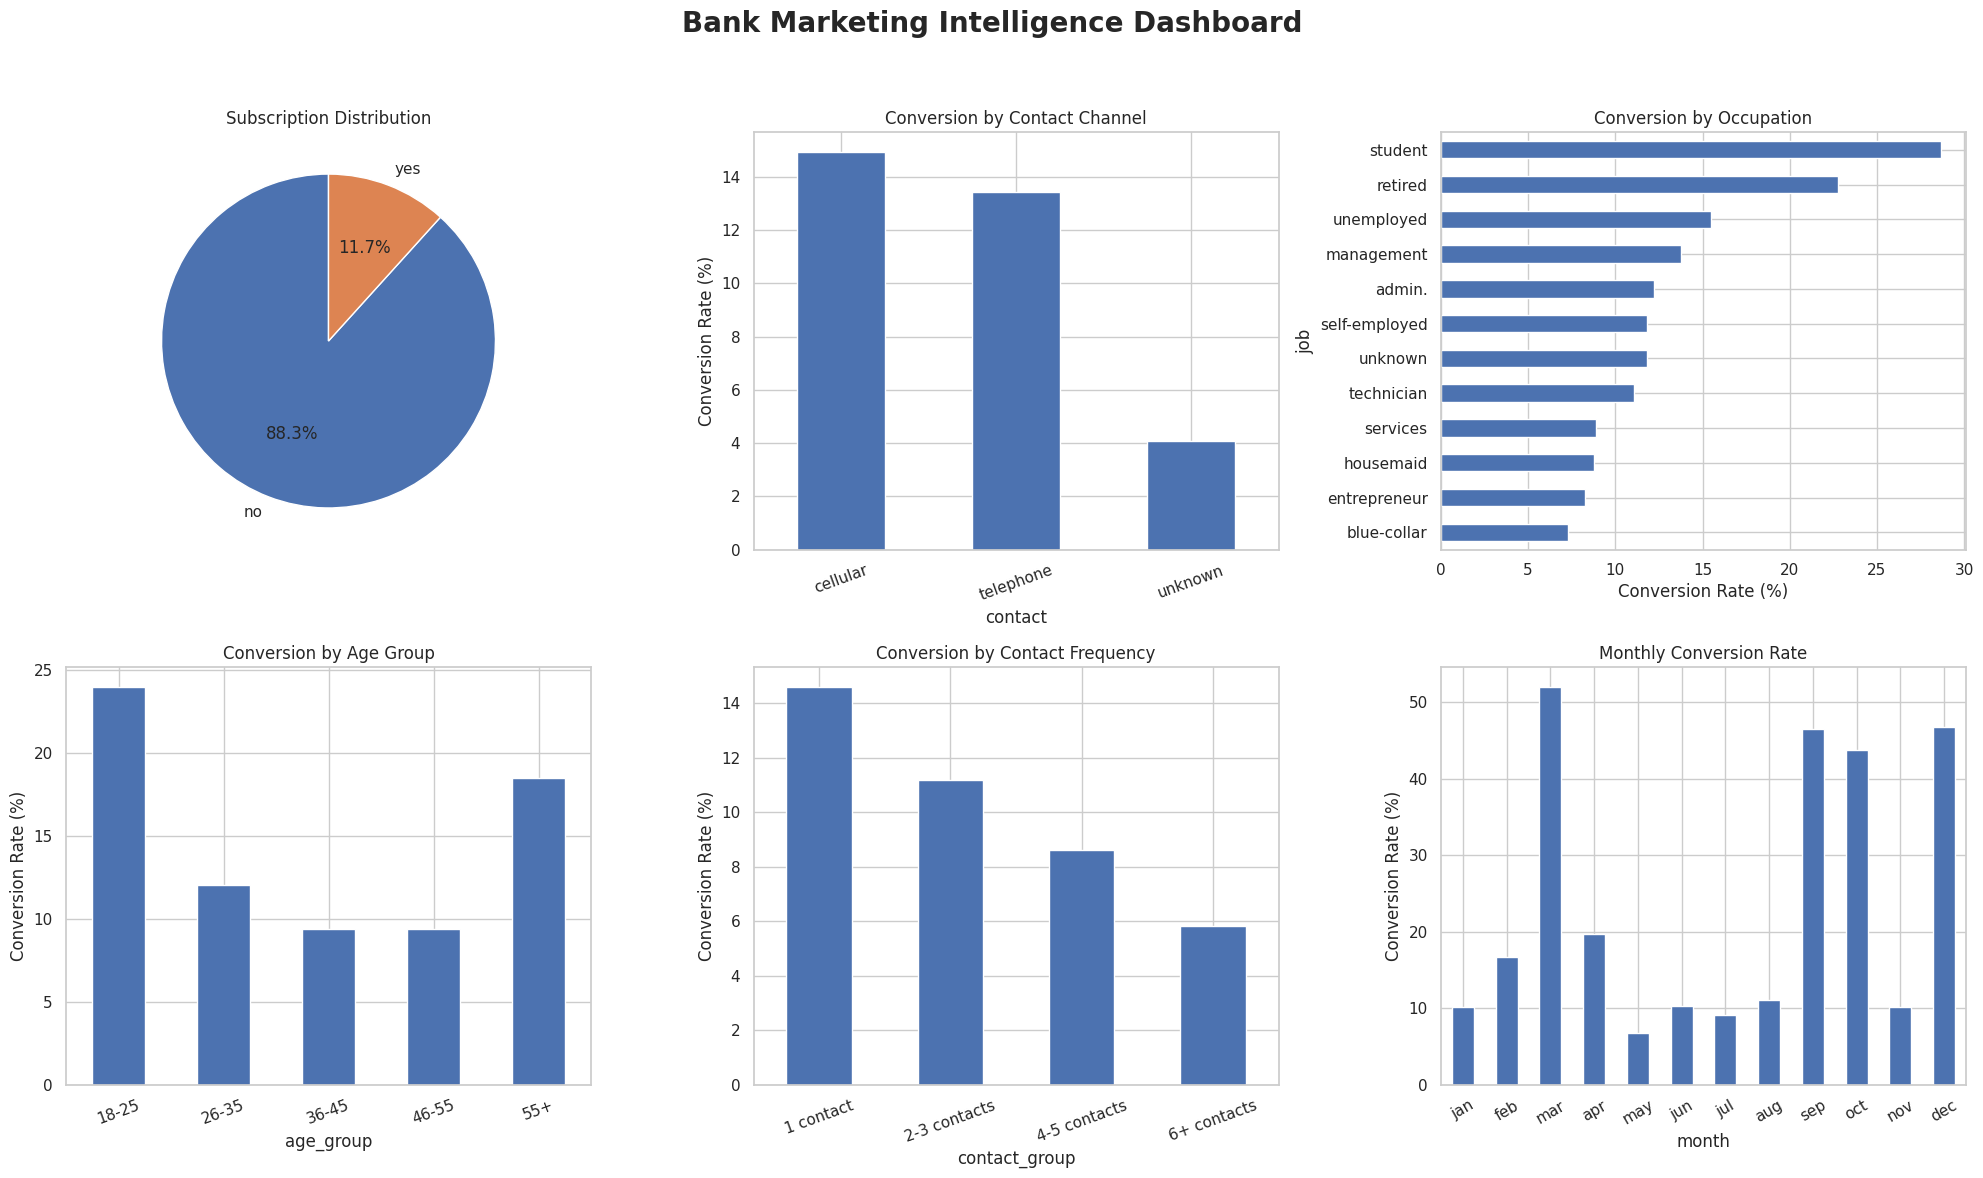

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle(
    "Bank Marketing Intelligence Dashboard",
    fontsize=20,
    fontweight="bold"
)

# 1. Overall subscription distribution
target = bank["subscribed"].value_counts()
axes[0, 0].pie(
    target,
    labels=target.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[0, 0].set_title("Subscription Distribution")

# 2. Contact channel conversion
contact = bank.groupby("contact")["subscribed_binary"].mean() * 100
contact.sort_values(ascending=False).plot(
    kind="bar", ax=axes[0, 1]
)
axes[0, 1].set_title("Conversion by Contact Channel")
axes[0, 1].set_ylabel("Conversion Rate (%)")
axes[0, 1].tick_params(axis="x", rotation=20)

# 3. Occupation conversion
job = (
    bank.groupby("job")
    .agg(records=("subscribed_binary", "size"),
         conversion=("subscribed_binary", "mean"))
)
job = job[job["records"] >= 100]
job["conversion"] = job["conversion"] * 100
job.sort_values("conversion").plot(
    y="conversion", kind="barh", ax=axes[0, 2],
    legend=False
)
axes[0, 2].set_title("Conversion by Occupation")
axes[0, 2].set_xlabel("Conversion Rate (%)")

# 4. Age group conversion
age = bank.groupby(
    "age_group", observed=False
)["subscribed_binary"].mean() * 100
age.plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Conversion by Age Group")
axes[1, 0].set_ylabel("Conversion Rate (%)")
axes[1, 0].tick_params(axis="x", rotation=20)

# 5. Contact frequency conversion
frequency = bank.groupby(
    "contact_group", observed=False
)["subscribed_binary"].mean() * 100
frequency.plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Conversion by Contact Frequency")
axes[1, 1].set_ylabel("Conversion Rate (%)")
axes[1, 1].tick_params(axis="x", rotation=20)

# 6. Monthly conversion
month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]
monthly = (
    bank.groupby("month")["subscribed_binary"]
    .mean().reindex(month_order) * 100
)
monthly.plot(kind="bar", ax=axes[1, 2])
axes[1, 2].set_title("Monthly Conversion Rate")
axes[1, 2].set_ylabel("Conversion Rate (%)")
axes[1, 2].tick_params(axis="x", rotation=30)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(
    "bank_marketing_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [14]:
import os

print("Dashboard generated:", os.path.exists("bank_marketing_dashboard.png"))
print("Dataset shape:", bank.shape)
print("Overall conversion:", round(bank["subscribed_binary"].mean() * 100, 2), "%")

Dashboard generated: True
Dataset shape: (45211, 22)
Overall conversion: 11.7 %


# 8. Conclusion & Business Recommendations

## Conclusion

This project analysed 45,211 records from the UCI Bank Marketing dataset to evaluate the effectiveness of direct marketing campaigns and understand customer subscription behaviour.

The overall term-deposit subscription rate was **11.70%**, indicating that only a relatively small proportion of contacted customers subscribed.

The analysis revealed several important patterns:

- **Previous campaign success:** Customers with a successful previous campaign outcome had a subscription rate of 64.73%, making previous campaign history an important indicator of customer response.
- **Occupation:** Students (28.68%) and retired customers (22.79%) recorded comparatively high subscription rates.
- **Age:** Subscription rates were relatively high among customers aged 18–25 (23.95%) and 55+ (18.49%).
- **Contact channel:** Cellular contacts recorded a 14.92% subscription rate, compared with 13.42% for telephone contacts.
- **Contact frequency:** Customers contacted once had a 14.60% subscription rate, while the rate declined to 5.81% among customers contacted six or more times.
- **Monthly performance:** March, December and September recorded the highest subscription rates, although some of these months had relatively small sample sizes.

## Business Recommendations

Based on the observed patterns, the following strategies could be explored:

1. **Prioritise customer history:** Consider previous campaign success when designing customer outreach strategies.
2. **Improve customer segmentation:** Develop differentiated marketing approaches for customer groups with varying subscription patterns.
3. **Optimise contact frequency:** Investigate whether excessive repeated contacts are reducing customer engagement.
4. **Evaluate communication channels:** Explore the effectiveness of cellular outreach while considering customer preferences and contact availability.
5. **Plan campaigns strategically:** Examine seasonal variations before allocating marketing resources across different months.

## Limitations

- The dataset is observational; therefore, the identified relationships should not be interpreted as causal effects.
- Campaign expenditure and revenue information are unavailable, preventing direct calculation of ROI or customer acquisition cost.
- The analysis describes historical campaign behaviour and does not establish that the same patterns will hold in future campaigns.
- The `duration` variable represents call duration and is only known after a call. It should not be used in a pre-call customer targeting strategy.

## Final Takeaway

The project demonstrates how Python-based exploratory data analysis, feature engineering, SQL querying and visualization can transform raw banking campaign data into meaningful business insights.

It highlights the importance of customer segmentation, campaign history and contact strategy in understanding marketing effectiveness and supporting data-driven decision-making.